# Forecast opponent skills with a typed aircraft–missile graph

Run **17_prepare_enemy_missile_nn_duel_skill_forecasting.ipynb** first. This notebook
uses its exact verified **115-channel** dataset: the original 54 numeric channels,
28 reconstructed enemy-missile channels and 33 current own-skill indicators per
frame. The 51-frame past history and +1/+2/+5-second opponent-skill targets remain
unchanged. The loader rejects the older 87-channel datasets.

The temporal backbone and objective match notebook 18:
**width 96, two Transformer layers, six attention heads and dropout 0.25**. Training
retains disjoint raw histories across both views of each flight, L1 regularisation,
early stopping without a 50-epoch minimum, and overtraining shutdown. Three seeds
(42, 43, 44) run for at most 100 epochs each. All executable cells are timed.

Each enemy slot contains observer-relative North/West/Up position, relative velocity
and range. Preparation translates the opposite view's same-time friendly slots;
only missile values and current relative aircraft geometry enter those 28 channels.
There are no future missile samples or opponent-skill inputs. Enemy tracks follow
the source's idealised simulator availability; inference requires equivalent
contemporaneous enemy-missile tracks and exactly the saved feature ordering/scaling.

Per-horizon inverse-square-root class weights are fitted on retained training
labels only, with a rare/common ratio cap of 5 and training-frequency mean weight
one. Missing targets remain independently masked; zero-support classes are audited.
Unweighted evaluation NLL still selects checkpoints and drives stopping. All seeds
finish before held-out validation is evaluated. Compare per-class recall/F1 and
supported macro-F1 alongside NLL, accuracy and calibration; weighting may trade some
common-class accuracy or calibration for rare-class recall.

Data receipts, runs and the default MLflow database use
`artifacts/nn_duel_enemy_missile_forecasting/`, in the separate
`nn-duel-enemy-missile-skill-forecasting` experiment. Override data with
`BVR_NN_ENEMY_MISSILE_DATA`, or disable tracking with
`BVR_NN_ENEMY_MISSILE_MLFLOW=0`. Use fresh runs for this input schema; resume requires
unchanged source, data and configuration. Counts/weights are saved and logged.

Install `.[ml]` and an IPython/Jupyter kernel. CUDA uses BF16 where supported; CPU
uses FP32. Streaming avoids caching the full approximately 18.1 GiB frame array on
a 16 GiB GPU. Catalogue selections remain labels for issued skills, rather than
proof of distinct executed physical manoeuvres.

Architecture ID: `typed_graph`. **Run All trains three independent seeds**
and saves their final diagnostic artifacts. To rebuild reports from saved runs,
set `TRAIN_MODEL=False` and list `EXISTING_RUNS`. No new data preparation or
simulator collection is performed here. All three architecture notebooks consume
the exact notebook-17 dataset receipt.

Each frame becomes two aircraft nodes and up to eight missile nodes. Two
residual, typed edge-conditioned message blocks combine aircraft relationships,
missile ownership and potential threats using current relative geometry.
Masked mean, max and count summaries make missile-slot ordering irrelevant.
Only the observing aircraft's current skill is known. The 51-frame temporal
sequence contains graph readouts, not recurrent states for numbered missile
slots: slot compaction therefore cannot create a false track identity.

This is a supervised adaptation of object/relationship aggregation concepts in
[Huo et al. (2025)](https://doi.org/10.1038/s41598-025-00463-y), not its PPO/RACOS
controller or a reproduction of its combat win-rate experiments.

The temporal backbone remains width 96, six heads, two layers and dropout 0.25.
Graph/set encoders use width 64; the graph has two message-passing blocks.
Parameter counts are recorded rather than assumed equal. Diagnostic outputs for
all seeds and a `comparisons/latest_typed_graph_runs.json` receipt are saved.
Notebook 21 compares these receipts, with explicit run lists supported for older
experiments. Receipts are overwritten by the latest *completed* family run;
copy or explicitly list run paths to freeze a particular comparison.

Graph message sum/max/count reductions and residual updates use **FP32**,
while linear layers retain optional BF16 autocast. This avoids mixing FP32
node states with BF16 message masks/scatter buffers. After pulling a model
fix, restart the kernel and start fresh graph runs; reuse notebook 17 data.


In [1]:
%%time
from pathlib import Path
import os
import sys

root_override = os.environ.get("BVR_NN_ROOT")
candidates = ([Path(root_override).expanduser()] if root_override else
              [Path.cwd(), *Path.cwd().parents])
ROOT = next((p.resolve() for p in candidates
             if (p / "bvr_behavior_prediction/nn_duel_skill_forecasting.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Set BVR_NN_ROOT to the full Trajectory_Classification checkout path.")
sys.path.insert(0, str(ROOT))
from bvr_behavior_prediction.notebook_runtime import require_pyarrow
require_pyarrow()  # Report the kernel environment and native-library repair steps.
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from bvr_behavior_prediction import nn_duel_skill_forecasting as duel_data
from bvr_behavior_prediction.paired_skill_forecasting import (
    HORIZONS, HISTORY_STEPS, RAW_HISTORY_STEPS, SPLITS, read_json, write_json, sha256,
)
DATA_ROOT = ROOT / "artifacts/nn_duel_enemy_missile_forecasting"
EXPERIMENT_ROOT = ROOT / "artifacts/nn_duel_enemy_missile_forecasting"
EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)

import torch
from bvr_behavior_prediction.paired_skill_forecasting import (
    DEFAULT_TRAINING, train_model, final_evaluation, metric_tables, resolve_precision,
    fit_class_weighting, class_weight_table,
)
from bvr_behavior_prediction.paired_skill_tracking import log_run_artifacts
from bvr_behavior_prediction.enemy_missile_diagnostics import save_diagnostics

DATA_OVERRIDE = os.environ.get("BVR_NN_ENEMY_MISSILE_DATA")
if not DATA_OVERRIDE and not (DATA_ROOT / "latest_dataset.json").exists():
    raise FileNotFoundError("Run notebook 17 first, or set BVR_NN_ENEMY_MISSILE_DATA to its dataset directory.")
receipt = None if DATA_OVERRIDE else read_json(DATA_ROOT / "latest_dataset.json")
DATA = Path(DATA_OVERRIDE or receipt["directory"]).expanduser().resolve()
if receipt and sha256(DATA / "manifest.json") != receipt["manifest_sha256"]:
    raise ValueError("The prepared dataset changed since notebook 17 completed.")
data = duel_data.EnemyMissileNNDuelData(DATA)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TRAINING_SEEDS = [42, 43, 44]  # One independently fitted three-horizon NN per seed.
ARCHITECTURE = "typed_graph"
TRAIN_MODEL = True
REEVALUATE_SAVED = False  # Explicitly enable to replace already-saved final evaluations.
RESUME = False
EXISTING_RUNS = {}  # For resume/report-only: {42: r"C:\...\runs\nn-duel-enemy-missile-s42_...", ...}.
if not TRAINING_SEEDS or len(set(TRAINING_SEEDS)) != len(TRAINING_SEEDS):
    raise ValueError("Choose at least one distinct training seed.")
if (RESUME or not TRAIN_MODEL) and set(EXISTING_RUNS) != set(TRAINING_SEEDS):
    raise ValueError("Set EXISTING_RUNS for every selected seed when resuming or reporting.")
RUN_STAMP = pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
RUNS = {seed: Path(EXISTING_RUNS[seed]).expanduser().resolve() if seed in EXISTING_RUNS
        else EXPERIMENT_ROOT / "runs" / f"nn-duel-enemy-missile-{ARCHITECTURE}-s{seed}_{RUN_STAMP}"
        for seed in TRAINING_SEEDS}
CONFIG = dict(DEFAULT_TRAINING)
CONFIG.update(architecture=ARCHITECTURE, width=96, heads=6, layers=2,
              graph_width=64, graph_layers=2, dropout=0.25, epochs=100, early_stopping=True, early_stopping_min_epochs=0,
              early_stopping_patience=10, l1_lambda=1e-6,
              class_weighting="sqrt_inverse", max_class_weight_ratio=5.0,
              overtraining_shutdown=True, overtraining_patience=3,
              overtraining_relative_increase=0.05, overtraining_min_gap=0.1,
              precision="bf16", evaluation_precision="fp32", evaluation_attention="math",
              batch_size=512,
              evaluation_batch_size=1024, data_backend="prefetch" if DEVICE == "cuda" else "direct",
              num_workers=2, cpu_threads=4, compile_model=False)
MLFLOW_ENABLED = os.environ.get("BVR_NN_ENEMY_MISSILE_MLFLOW", "1") == "1"
MLFLOW_TRACKING_URI = os.environ.get("MLFLOW_TRACKING_URI",
    f"sqlite:///{(EXPERIMENT_ROOT / 'mlflow.db').as_posix()}")
TRACKING = {"enabled": MLFLOW_ENABLED, "tracking_uri": MLFLOW_TRACKING_URI,
            "experiment": "nn-duel-enemy-missile-skill-forecasting", "log_per_class": True,
            "log_model": True,
            "artifact_root": (EXPERIMENT_ROOT / "mlflow_artifacts").as_uri()
                             if MLFLOW_TRACKING_URI.startswith("sqlite:") else None}
print("Prepared dataset:", DATA)
print("Model run directories:", {s: str(p) for s, p in RUNS.items()})
display(pd.Series({**CONFIG, "device": DEVICE,
    "effective_precision": resolve_precision(DEVICE, CONFIG["precision"]),
    "input_features": len(data.manifest["features"]), "classes": len(data.classes),
    "history_steps": HISTORY_STEPS, "horizons_s": HORIZONS}))
display(pd.DataFrame(data.manifest["counts"]).T)
if MLFLOW_ENABLED and MLFLOW_TRACKING_URI.startswith("sqlite:"):
    print(f'mlflow ui --backend-store-uri "{MLFLOW_TRACKING_URI}" --host 127.0.0.1 --port 5000')
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.synchronize()

# This audit reads only labels retained in the training partition.
CLASS_WEIGHTING = fit_class_weighting(data, CONFIG)
CLASS_WEIGHT_AUDIT = class_weight_table(CLASS_WEIGHTING)
with pd.option_context("display.max_rows", None):
    display(CLASS_WEIGHT_AUDIT.pivot(index="skill", columns="horizon_s",
                                    values=["training_support", "weight"]).round(4))
print("Zero-training-support skill/horizon pairs:")
display(CLASS_WEIGHT_AUDIT.loc[CLASS_WEIGHT_AUDIT.training_support.eq(0)])


Prepared dataset: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_enemy_missile_forecasting\data\eee3474c5493_5b951842316d_a5deacfc_f8d91289
Model run directories: {42: 'C:\\Users\\theon\\Trajectory_Classification\\artifacts\\nn_duel_enemy_missile_forecasting\\runs\\nn-duel-enemy-missile-typed_graph-s42_20261109T212034693131Z', 43: 'C:\\Users\\theon\\Trajectory_Classification\\artifacts\\nn_duel_enemy_missile_forecasting\\runs\\nn-duel-enemy-missile-typed_graph-s43_20261109T212034693131Z', 44: 'C:\\Users\\theon\\Trajectory_Classification\\artifacts\\nn_duel_enemy_missile_forecasting\\runs\\nn-duel-enemy-missile-typed_graph-s44_20261109T212034693131Z'}


epochs                                     100
seed                                        42
batch_size                                 512
evaluation_batch_size                     1024
learning_rate                           0.0003
weight_decay                              0.01
gradient_clip                              1.0
width                                       96
heads                                        6
layers                                       2
dropout                                   0.25
early_stopping                            True
early_stopping_min_epochs                    0
early_stopping_patience                     10
precision                                 bf16
data_backend                          prefetch
num_workers                                  2
prefetch_factor                              2
cpu_threads                                  4
loader_timeout                              60
compile_model                            False
compile_mode 

,groups,episodes,windows,labels_by_horizon
train,4000,8000,137001,"[137001, 136791, 136135]"
test,3000,6000,1224086,"[1224086, 1218086, 1200100]"
validation,3000,6000,1224414,"[1224414, 1218414, 1200422]"


mlflow ui --backend-store-uri "sqlite:///C:/Users/theon/Trajectory_Classification/artifacts/nn_duel_enemy_missile_forecasting/mlflow.db" --host 127.0.0.1 --port 5000
GPU: NVIDIA GeForce RTX 5080 Laptop GPU


training_support                    weight                
horizon_s                          1        2        5       1       2       5
skill                                                                         
abort_support                  173.0    169.0    168.0  3.0238  3.0267  3.0336
accelerate_to_speed              1.0      1.0      0.0  3.0238  3.0267  0.0000
beam_missile_left               34.0     29.0     22.0  3.0238  3.0267  3.0336
beam_missile_right             132.0    130.0    113.0  3.0238  3.0267  3.0336
beam_target_left              5543.0   5524.0   5370.0  1.5949  1.6008  1.6351
beam_target_right             2644.0   2595.0   2436.0  2.3093  2.3356  2.4277
climb_to_altitude                1.0      3.0      2.0  3.0238  3.0267  3.0336
commit                           0.0      1.0      1.0  0.0000  3.0267  3.0336
crank_target_left             2179.0   2099.0   1760.0  2.5438  2.5970  2.8561
crank_target_right            4229.0   4220.0   4253.0  1.8259  1.8315  1.8373
decelerate_to_speed            409.0    402.0    356.0  3.0238  3.0267  3.0336
defensive_reversal              54.0     52.0     45.0  3.0238  3.0267  3.0336
descend_to_altitude            382.0    360.0    319.0  3.0238  3.0267  3.0336
dive_defense                     1.0      0.0      0.0  3.0238  0.0000  0.0000
drag_missile                     5.0      4.0      4.0  3.0238  3.0267  3.0336
extend                       11173.0  11164.0  11176.0  1.1234  1.1261  1.1334
lag_pursuit                  21647.0  21660.0  21628.0  0.8071  0.8084  0.8147
last_ditch_break                 5.0      4.0      3.0  3.0238  3.0267  3.0336
launch                         321.0    303.0    278.0  3.0238  3.0267  3.0336
lead_pursuit                  2150.0   2132.0   2080.0  2.5609  2.5768  2.6272
lock_target                      7.0      6.0      5.0  3.0238  3.0267  3.0336
maintain_heading                39.0     39.0     27.0  3.0238  3.0267  3.0336
notch_left                     183.0    177.0    154.0  3.0238  3.0267  3.0336
notch_right                     78.0     75.0     65.0  3.0238  3.0267  3.0336
preemptive_crank                 6.0      4.0      3.0  3.0238  3.0267  3.0336
pursue_target                 6037.0   6046.0   6027.0  1.5282  1.5302  1.5434
recommit                     38551.0  38631.0  39001.0  0.6048  0.6053  0.6067
search                           7.0      5.0      6.0  3.0238  3.0267  3.0336
secondary_shot               11696.0  11690.0  11656.0  1.0980  1.1004  1.1098
short_range_attack             560.0    530.0    476.0  3.0238  3.0267  3.0336
support_missile                116.0    123.0    105.0  3.0238  3.0267  3.0336
turn_cold                    28569.0  28542.0  28538.0  0.7025  0.7043  0.7093
turn_to_heading                 69.0     71.0     58.0  3.0238  3.0267  3.0336

Zero-training-support skill/horizon pairs:


,horizon_s,skill,training_support,training_frequency,weight
7,1,commit,0,0.0,0.0
46,2,dive_defense,0,0.0,0.0
67,5,accelerate_to_speed,0,0.0,0.0
79,5,dive_defense,0,0.0,0.0


CPU times: total: 1min 9s
Wall time: 1min 57s


## Fit independently seeded networks

Let `n[h,c]` be the number of retained training labels for class `c` at horizon
`h`, ignoring missing targets (`-1`), and `n_max[h]` the largest such class count.
For classes seen during training, form

`r[h,c] = min(5, sqrt(n_max[h] / n[h,c]))`

and normalise by the training-frequency weighted mean:

`w[h,c] = r[h,c] / sum_c(training_frequency[h,c] * r[h,c])`.

The rare/common per-example loss ratio is at most 5. For example, an uncapped 16:1
support ratio gives rare examples four times the weight of common examples. The
frequency-weighted mean weight is one for each horizon, keeping the expected loss
scale comparable with unweighted CE and L1. Zero-support classes receive zero
positive-target weight and retain their output logits. Their absence is audited.

For each horizon, average `w[h,y] * (-log p[h,y])` over its valid labels; then average
the represented horizons equally. The denominator is the number of valid labels,
not the minibatch sum of weights: weights remain effective even when a minibatch
contains just one class. Missing labels contribute neither loss nor gradient.
The masked weighted cross-entropy is implemented in FP32 under BF16 training too.

The loss uses independent missing-label masks. Scaling and the split are fixed by notebook 17 for every seed.
The training objective adds `l1_lambda * sum(abs(model_weights))` (default `1e-6`) to
masked class-weighted cross-entropy. This includes trainable matrix/tensor weights and position
embeddings, excluding biases and LayerNorm scales. AdamW weight decay remains 0.01.
Train/test NLL is evaluated without L1, in evaluation mode; checkpoint selection
therefore remains comparable across epochs. History records the L1 contribution,
evaluation-mode weighted training cross-entropy (`train_data_loss`), its sum with
L1 (`train_objective`), and the unweighted test-minus-train NLL gap separately.
Unweighted mean test NLL still selects checkpoints and drives both stopping rules;
the objective is not changed to favour a checkpoint based on weighted test scores.

Early-stopping patience counts from epoch one: ten consecutive epochs without a
new all-time minimum test NLL stop the run (earliest plateau stop: epoch 11).
There is no minimum training duration. A separate overtraining shutdown stops after
three consecutive epochs where all of these hold: test NLL exceeds its best by
more than 5%, test-minus-train NLL exceeds 0.1, and train NLL is below its value at
the best-test checkpoint. A recovery resets this counter. These are configurable
starting thresholds, not tuned guarantees. The shutdown acts independently of
ordinary patience and preserves `best.pt`; counters and the stop reason survive
resume. Set both `early_stopping=False` and `overtraining_shutdown=False` to run
the full epoch budget. `RESUME=True` requires the same source, data and configuration.
Checkpoint input dimensions, feature ordering and dataset digest are stored with weights.

**Evaluation policy:** training can use CUDA BF16, while checkpoint selection and
final evaluation explicitly use `evaluation_precision="fp32"` and
`evaluation_attention="math"`. This keeps FP32 cross-entropy and unweighted NLL,
and isolates evaluation from CUDA BF16 and fused inference-attention kernels.
This is a conservative evaluation policy, not a confirmed diagnosis of the reported
GPU failure. It is held fixed across notebooks 18–20. Persistent failures write
`nonfinite_evaluation.json` in the run directory with the processing stage and
sample details; do not replace nonfinite values or discard those examples.

After pulling the fix, **restart the Jupyter kernel**, then run the setup and
training cells with `RESUME=False`, `EXISTING_RUNS={}` and fresh timestamped runs.
A first-epoch failure may have saved no complete epoch checkpoint. Source/config
resume guards remain strict; do not resume an older run under changed code.
The existing notebook-17 dataset receipt is still compatible; no new preparation
or collection is required. Reuse complete historical final outputs only in
report-only mode with `TRAIN_MODEL=False` and `REEVALUATE_SAVED=False`.


In [2]:
%%time
histories = {}
def epoch_output(row, summary, per_class):
    print(f"Epoch {row['epoch']}: train NLL={row['train_nll']:.5f}, "
          f"test NLL={row['test_nll']:.5f}, "
          f"weighted train CE={row['train_data_loss']:.5f}, "
          f"L1={row['train_l1_penalty']:.5f}, "
          f"gap={row['generalization_gap']:.5f}, "
          f"overtraining streak={row['overtraining_epochs']}, {row['seconds']:.1f}s", flush=True)
    display(summary[["split", "horizon_s", "nll", "accuracy", "macro_f1",
                     "supported_macro_f1", "weighted_f1"]].round(4))
    with pd.option_context("display.max_rows", None):
        display(per_class.pivot(index=["horizon_s", "skill"], columns="split",
                                 values=["class_nll", "f1", "support"]).round(4))

for seed, run in RUNS.items():
    print(f"Training seed {seed}: {run}", flush=True)
    config = {**CONFIG, "seed": seed}
    tracking = {**TRACKING, "run_name": run.name}
    if TRAIN_MODEL:
        histories[seed] = train_model(data, run, config, callback=epoch_output,
                                     device=DEVICE, resume=RESUME, tracking=tracking)
    else:
        histories[seed] = pd.read_csv(run / "history.csv")
    status = read_json(run / "training_status.json")
    if status["status"] not in {"completed", "early_stopped"}:
        raise ValueError(f"Training has not concluded for seed {seed}.")
    saved_run = read_json(run / "run.json")
    if saved_run["data_manifest_sha256"] != sha256(DATA / "manifest.json"):
        raise ValueError(f"Saved seed {seed} belongs to a different prepared dataset.")
    if saved_run["classes"] != data.classes or saved_run["feature_names"] != data.manifest["features"]:
        raise ValueError(f"Saved seed {seed} has a different catalogue or feature ordering.")
    saved_training = dict(saved_run["training"])
    expected_training = dict(config)
    if not TRAIN_MODEL and not RESUME and not REEVALUATE_SAVED:
        # Reading completed historical outputs does not change their evaluation
        # policy. New evaluation settings may differ only in this report-only path.
        evaluation_keys = ("evaluation_precision", "evaluation_attention")
        historical_evaluation = any(saved_training.get(key) != expected_training.get(key)
                                    for key in evaluation_keys)
        required_saved_finals = ["final_metrics.csv", "final_per_class.csv", "selection.json",
                                 *[f"final_{split}.npz" for split in SPLITS]]
        if historical_evaluation and not all((run / name).is_file() for name in required_saved_finals):
            raise ValueError("Historical evaluation settings require complete saved final outputs "
                             "for report-only use; start a fresh run for the new policy.")
        for key in evaluation_keys:
            saved_training.pop(key, None)
            expected_training.pop(key, None)
    if saved_training != expected_training:
        raise ValueError(f"Requested configuration differs from saved seed {seed}.")
    display(histories[seed].tail())
if DEVICE == "cuda":
    torch.cuda.synchronize()


Training seed 42: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_enemy_missile_forecasting\runs\nn-duel-enemy-missile-typed_graph-s42_20261109T212034693131Z


C:\Users\theon\.conda\envs\trajectory-nn-clean\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow run: 08c9796de5ab426dac3a96b2c7ba0200 (nn-duel-enemy-missile-skill-forecasting)
Runtime: cuda, bf16, prefetch, batch 512, evaluation batch 1024, frame cache 0.000 GiB
Evaluation: fp32, math attention
Epoch 1: train NLL=1.81199, test NLL=1.80302, weighted train CE=2.02393, L1=0.01871, gap=-0.00897, overtraining streak=0, 171.6s


,split,horizon_s,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1
0,train,1,1.8137,0.3558,0.0837,0.0863,0.3448
1,train,2,1.8169,0.3549,0.0779,0.0803,0.3398
2,train,5,1.8055,0.3581,0.0817,0.0870,0.3476
3,test,1,1.8026,0.3633,0.0840,0.0840,0.3541
4,test,2,1.8067,0.3603,0.0790,0.0790,0.3471
5,test,5,1.7997,0.3614,0.0805,0.0805,0.3526


class_nll              f1           support  \
split                              test   train    test   train      test   
horizon_s skill                                                             
1         abort_support          4.6473  4.4489  0.0000  0.0000    1488.0   
          accelerate_to_speed    6.0749  4.5415  0.0000  0.0000       2.0   
          beam_missile_left      4.6458  4.6060  0.0000  0.0000     253.0   
          beam_missile_right     3.8989  3.8036  0.0000  0.0000    1073.0   
          beam_target_left       2.3651  2.4052  0.0588  0.0503   49072.0   
          beam_target_right      2.8307  2.8453  0.0172  0.0163   22525.0   
          climb_to_altitude      4.0667  3.9828  0.0000  0.0000      20.0   
          commit                 7.4905     NaN  0.0000  0.0000       2.0   
          crank_target_left      2.4743  2.4149  0.2277  0.2427   17193.0   
          crank_target_right     2.2103  2.2361  0.1911  0.1883   37913.0   
          decelerate_to_speed    2.3540  2.3924  0.1778  0.1664    3324.0   
          defensive_reversal     5.3523  5.2354  0.0000  0.0000     455.0   
          descend_to_altitude    3.3734  3.3288  0.0000  0.0000    3126.0   
          dive_defense           4.7257  6.4267  0.0000  0.0000       9.0   
          drag_missile           5.6919  5.4881  0.0000  0.0000      39.0   
          extend                 1.7771  1.7790  0.3398  0.3389  100323.0   
          lag_pursuit            1.9226  1.9229  0.2841  0.2686  194366.0   
          last_ditch_break       6.4345  8.3968  0.0000  0.0000      17.0   
          launch                 4.1501  4.0931  0.0000  0.0000    2710.0   
          lead_pursuit           2.6104  2.5450  0.1075  0.1488   19044.0   
          lock_target            5.7023  5.5032  0.0000  0.0000      60.0   
          maintain_heading       5.6362  5.8094  0.0000  0.0000     309.0   
          notch_left             3.2390  3.2024  0.0000  0.0000    1479.0   
          notch_right            5.1110  5.2783  0.0000  0.0000     635.0   
          preemptive_crank       4.9849  5.9028  0.0000  0.0000      40.0   
          pursue_target          2.5522  2.5775  0.0009  0.0007   54139.0   
          recommit               1.4714  1.4709  0.4735  0.4630  347921.0   
          search                 5.0461  5.9073  0.0000  0.0000      52.0   
          secondary_shot         1.7226  1.7443  0.4403  0.4368  104198.0   
          short_range_attack     2.5380  2.4838  0.0000  0.0000    4443.0   
          support_missile        3.9861  3.9692  0.0000  0.0000     981.0   
          turn_cold              1.5450  1.5539  0.4540  0.4422  256315.0   
          turn_to_heading        4.5645  4.6007  0.0000  0.0000     560.0   
2         abort_support          5.0900  4.8736  0.0000  0.0000    1477.0   
          accelerate_to_speed    6.6494  5.3093  0.0000  0.0000       2.0   
          beam_missile_left      5.0749  4.9630  0.0000  0.0000     248.0   
          beam_missile_right     3.9780  3.9374  0.0000  0.0000    1015.0   
          beam_target_left       2.4223  2.4515  0.0132  0.0108   48555.0   
          beam_target_right      2.7655  2.7795  0.1051  0.0919   22040.0   
          climb_to_altitude      4.5099  4.5425  0.0000  0.0000      19.0   
          commit                 6.4482  5.3347  0.0000  0.0000       2.0   
          crank_target_left      2.4612  2.3808  0.2125  0.2332   16215.0   
          crank_target_right     2.2487  2.2702  0.2034  0.1938   37773.0   
          decelerate_to_speed    2.5375  2.5703  0.0000  0.0000    3202.0   
          defensive_reversal     5.5106  5.4111  0.0000  0.0000     434.0   
          descend_to_altitude    3.2860  3.2705  0.0000  0.0000    2988.0   
          dive_defense           5.2321     NaN  0.0000  0.0000       9.0   
          drag_missile           6.0070  5.7615  0.0000  0.0000      39.0   
          extend                 1.7424  1.7360  0.3304  0.3362  100121.0   
          lag_pursuit     

Epoch 2: train NLL=1.61213, test NLL=1.59607, weighted train CE=1.87080, L1=0.01869, gap=-0.01606, overtraining streak=0, 151.7s


... (342 outputs left out)

class_nll              f1           support  \
split                              test   train    test   train      test   
horizon_s skill                                                             
1         abort_support          4.7485  2.6902  0.0696  0.2929    1488.0   
          accelerate_to_speed    8.4450  5.7972  0.0000  0.0000       2.0   
          beam_missile_left      4.4212  3.8025  0.0000  0.0000     253.0   
          beam_missile_right     2.3146  1.7450  0.3306  0.4189    1073.0   
          beam_target_left       0.9719  0.8814  0.6682  0.6987   49072.0   
          beam_target_right      1.1957  0.8960  0.5165  0.5901   22525.0   
          climb_to_altitude      9.4689  7.5920  0.0000  0.0000      20.0   
          commit                10.8648     NaN  0.0000  0.0000       2.0   
          crank_target_left      1.0893  0.7268  0.5410  0.6145   17193.0   
          crank_target_right     1.0603  0.8944  0.6512  0.6986   37913.0   
          decelerate_to_speed    1.7179  1.4690  0.2533  0.3578    3324.0   
          defensive_reversal     2.1894  1.8704  0.3102  0.4262     455.0   
          descend_to_altitude    1.6465  0.9583  0.5649  0.6332    3126.0   
          dive_defense          11.5748  7.0179  0.0000  0.0000       9.0   
          drag_missile           6.4263  3.6700  0.0000  0.0000      39.0   
          extend                 1.3408  1.0355  0.4685  0.5453  100323.0   
          lag_pursuit            1.4196  1.1696  0.3799  0.4699  194366.0   
          last_ditch_break      10.0205  7.0801  0.0000  0.0000      17.0   
          launch                 3.2031  2.3093  0.1474  0.2674    2710.0   
          lead_pursuit           2.1560  0.9199  0.3446  0.4975   19044.0   
          lock_target            4.9274  3.1547  0.0000  0.0000      60.0   
          maintain_heading       4.3039  2.8849  0.0603  0.1455     309.0   
          notch_left             2.2096  1.7667  0.2973  0.3886    1479.0   
          notch_right            3.5822  2.7620  0.0515  0.1651     635.0   
          preemptive_crank       7.7566  4.2500  0.0000  0.0000      40.0   
          pursue_target          1.8153  1.1066  0.3292  0.4903   54139.0   
          recommit               1.1822  1.0766  0.5782  0.6111  347921.0   
          search                 6.8590  4.4275  0.0000  0.0000      52.0   
          secondary_shot         1.3206  1.0944  0.5614  0.6355  104198.0   
          short_range_attack     1.5752  1.2194  0.3383  0.4267    4443.0   
          support_missile        3.7792  2.8044  0.0189  0.2083     981.0   
          turn_cold              1.0621  0.9646  0.5236  0.5692  256315.0   
          turn_to_heading        3.7215  3.5387  0.0000  0.0286     560.0   
2         abort_support          4.7670  2.6456  0.0704  0.3022    1477.0   
          accelerate_to_speed    8.4077  5.1457  0.0000  0.0000       2.0   
          beam_missile_left      4.6309  3.6319  0.0000  0.1290     248.0   
          beam_missile_right     2.3850  1.8602  0.2758  0.3986    1015.0   
          beam_target_left       0.9815  0.8849  0.6587  0.6954   48555.0   
          beam_target_right      1.2239  0.9315  0.5072  0.5884   22040.0   
          climb_to_altitude      8.6125  5.3903  0.0000  0.0000      19.0   
          commit                12.1783  6.4452  0.0000  0.0000       2.0   
          crank_target_left      1.1491  0.7544  0.5154  0.5956   16215.0   
          crank_target_right     1.1131  0.9418  0.6475  0.6911   37773.0   
          decelerate_to_speed    1.7024  1.4378  0.2735  0.3649    3202.0   
          defensive_reversal     2.2456  1.8977  0.3197  0.4320     434.0   
          descend_to_altitude    1.7707  0.9738  0.5451  0.6331    2988.0   
          dive_defense          13.8778     NaN  0.0000  0.0000       9.0   
          drag_missile           6.6238  4.0543  0.0000  0.0000      39.0   
          extend                 1.3427  1.0322  0.4677  0.5460  100121.0   
          lag_pursuit     

Early stopping after epoch 44: patience; stale epochs=10, consecutive overtraining epochs=0. Best checkpoint: epoch 34.


,epoch,train_nll,test_nll,train_data_loss,train_l1_penalty,train_objective,generalization_gap,overtraining_detected,overtraining_epochs,stop_reason,train_macro_f1,test_macro_f1,improved,epochs_without_improvement,early_stopped,seconds
39,40,1.100317,1.293476,1.100351,0.020968,1.121319,0.193159,False,0,NaN,0.288593,0.229961,False,6,False,151.099041
40,41,1.084263,1.274171,1.102930,0.021024,1.123954,0.189908,False,0,NaN,0.286056,0.233663,False,7,False,151.135586
41,42,1.080360,1.301590,1.091426,0.021086,1.112512,0.221230,False,0,NaN,0.290944,0.225131,False,8,False,151.208834
42,43,1.075782,1.293541,1.096891,0.021135,1.118027,0.217759,False,0,NaN,0.289974,0.231271,False,9,False,151.330396
43,44,1.068635,1.283535,1.080884,0.021191,1.102075,0.214900,False,0,patience,0.303435,0.235454,False,10,True,151.035820


CPU times: total: 5h 27min 12s
Wall time: 4h 52min 49s


## Final evaluation, baseline and saved diagnostics

Every seed completes checkpoint selection before this cell reads validation.
Completed final predictions are reused unless `REEVALUATE_SAVED=True`. The
training-frequency baseline and diagnostic outputs are persisted for every seed,
then a receipt records the exact run list for notebook 21. No seed is chosen by
validation performance. A failed diagnostic export leaves the previous completed
receipt intact; fix the issue and rerun this cell using the same run paths.


In [4]:
%%time
# All selected seeds finish before accessing held-out validation. Reuse completed
# final evaluations by default; report-only execution does not re-evaluate models.
all_metrics = []
required_finals = ["final_metrics.csv", "final_per_class.csv", "selection.json",
                   *[f"final_{split}.npz" for split in SPLITS]]
for seed, run in RUNS.items():
    if not REEVALUATE_SAVED and all((run / name).is_file() for name in required_finals):
        best_epoch = read_json(run / "selection.json")["epoch"]
        summary = pd.read_csv(run / "final_metrics.csv")
        print(f"Reusing saved final evaluation: {run}")
    else:
        best_epoch, summary, scores, results = final_evaluation(
            data, run, DEVICE, tracking={**TRACKING, "run_name": run.name})
        del results  # Release full predictions before the next independent seed.
    all_metrics.append(summary.assign(seed=seed, selected_epoch=best_epoch))
    display(Markdown(f"**Seed {seed}, test-selected epoch {best_epoch}**"))
    display(summary.round(4))
comparison = pd.concat(all_metrics, ignore_index=True)
for run in RUNS.values():
    comparison.to_csv(run / "seed_comparison.csv", index=False)

frequency = np.zeros((3, len(data.classes)), np.float32)
for h in range(len(HORIZONS)):
    labels = data.targets[data.indices["train"], h]
    counts = np.bincount(labels[labels >= 0], minlength=len(data.classes))
    frequency[h] = (counts + 1) / (counts.sum() + len(data.classes))
baseline_rows = []
for split in SPLITS:
    labels = data.targets[data.indices[split]]
    probabilities = np.broadcast_to(frequency, (len(labels), *frequency.shape))
    baseline, _, _ = metric_tables(labels, probabilities, data.classes, split)
    baseline_rows.append(baseline)
baseline_metrics = pd.concat(baseline_rows, ignore_index=True)
for run in RUNS.values():
    baseline_metrics.to_csv(run / "training_frequency_baseline.csv", index=False)
display(baseline_metrics.assign(model="Training frequency").round(4))

# Persist tables, calibration, sample identities, plots and a diagnostic manifest
# for EVERY seed, independently of the report seed displayed below.
for seed, run in RUNS.items():
    saved = save_diagnostics(run, data=data)
    print(f"Persisted {ARCHITECTURE}, seed {seed}: {run / 'diagnostics'}")
    if MLFLOW_ENABLED:
        log_run_artifacts(run)

# This receipt names all requested runs; no winner is chosen from final scores.
receipt_path = EXPERIMENT_ROOT / "comparisons" / f"latest_{ARCHITECTURE}_runs.json"
receipt_path.parent.mkdir(parents=True, exist_ok=True)
write_json(receipt_path, {
    "architecture": ARCHITECTURE, "runs": [str(RUNS[s]) for s in TRAINING_SEEDS],
    "seeds": TRAINING_SEEDS, "data_manifest_sha256": sha256(DATA / "manifest.json"),
    "configuration": CONFIG,
})
print("Comparison receipt:", receipt_path)
if DEVICE == "cuda":
    torch.cuda.synchronize()


Reusing saved final evaluation: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_enemy_missile_forecasting\runs\nn-duel-enemy-missile-typed_graph-s42_20261109T212034693131Z


**Seed 42, test-selected epoch 27**

,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1
0,train,1,137001,1.1418,0.5386,0.2522,0.2601,0.5350
1,train,2,136791,1.1465,0.5373,0.2504,0.2582,0.5338
2,train,5,136135,1.1721,0.5287,0.2381,0.2534,0.5259
3,test,1,1224086,1.2377,0.5075,0.2259,0.2259,0.5043
4,test,2,1218086,1.2442,0.5061,0.2241,0.2241,0.5030
5,test,5,1200100,1.2678,0.4988,0.2093,0.2093,0.4962
6,validation,1,1224414,1.2418,0.4994,0.2199,0.2341,0.4959
7,validation,2,1218414,1.2484,0.4975,0.2185,0.2326,0.4942
8,validation,5,1200422,1.2724,0.4898,0.2026,0.2157,0.4869


Reusing saved final evaluation: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_enemy_missile_forecasting\runs\nn-duel-enemy-missile-typed_graph-s43_20261109T212034693131Z


**Seed 43, test-selected epoch 23**

,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1
0,train,1,137001,1.1736,0.5244,0.2513,0.2591,0.5235
1,train,2,136791,1.1765,0.5241,0.2533,0.2613,0.5235
2,train,5,136135,1.1992,0.5171,0.2337,0.2488,0.5171
3,test,1,1224086,1.2480,0.4996,0.2142,0.2142,0.5001
4,test,2,1218086,1.2531,0.4990,0.2130,0.2130,0.4997
5,test,5,1200100,1.2739,0.4929,0.1991,0.1991,0.4941
6,validation,1,1224414,1.2554,0.4918,0.2248,0.2394,0.4916
7,validation,2,1218414,1.2603,0.4909,0.2222,0.2365,0.4908
8,validation,5,1200422,1.2820,0.4844,0.2038,0.2169,0.4847


Reusing saved final evaluation: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_enemy_missile_forecasting\runs\nn-duel-enemy-missile-typed_graph-s44_20261109T212034693131Z


**Seed 44, test-selected epoch 34**

,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1
0,train,1,137001,1.1064,0.5507,0.2819,0.2907,0.5508
1,train,2,136791,1.1104,0.5498,0.2830,0.2919,0.5497
2,train,5,136135,1.1371,0.5412,0.2647,0.2818,0.5420
3,test,1,1224086,1.2465,0.5069,0.2378,0.2378,0.5083
4,test,2,1218086,1.2532,0.5058,0.2350,0.2350,0.5070
5,test,5,1200100,1.2751,0.4983,0.2156,0.2156,0.5002
6,validation,1,1224414,1.2540,0.4997,0.2383,0.2536,0.5010
7,validation,2,1218414,1.2605,0.4979,0.2356,0.2508,0.4991
8,validation,5,1200422,1.2824,0.4907,0.2175,0.2315,0.4927


,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1,model
0,train,1,137001,2.0901,0.2814,0.0133,0.0137,0.1236,Training frequency
1,train,2,136791,2.0845,0.2824,0.0133,0.0138,0.1244,Training frequency
2,train,5,136135,2.0636,0.2865,0.0135,0.0144,0.1276,Training frequency
3,test,1,1224086,2.0745,0.2842,0.0134,0.0134,0.1258,Training frequency
4,test,2,1218086,2.0687,0.2852,0.0135,0.0135,0.1266,Training frequency
5,test,5,1200100,2.0506,0.2882,0.0136,0.0136,0.1289,Training frequency
6,validation,1,1224414,2.0744,0.2843,0.0134,0.0143,0.1259,Training frequency
7,validation,2,1218414,2.0686,0.2853,0.0135,0.0143,0.1266,Training frequency
8,validation,5,1200422,2.0504,0.2882,0.0136,0.0144,0.1290,Training frequency


Persisted typed_graph, seed 42: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_enemy_missile_forecasting\runs\nn-duel-enemy-missile-typed_graph-s42_20261109T212034693131Z\diagnostics
MLflow run: 08c9796de5ab426dac3a96b2c7ba0200 (nn-duel-enemy-missile-skill-forecasting)
Persisted typed_graph, seed 43: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_enemy_missile_forecasting\runs\nn-duel-enemy-missile-typed_graph-s43_20261109T212034693131Z\diagnostics
MLflow run: 8572d48085a84c42a4b29159d3fbb90c (nn-duel-enemy-missile-skill-forecasting)
Persisted typed_graph, seed 44: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_enemy_missile_forecasting\runs\nn-duel-enemy-missile-typed_graph-s44_20261109T212034693131Z\diagnostics
MLflow run: 24de62dcbb904b24bf82f3854fa2e6f1 (nn-duel-enemy-missile-skill-forecasting)
Comparison receipt: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_enemy_missile_forecasting\comparisons\latest_typed_graph_runs.json
CPU time

## Persisted diagnostics for all seeds

Every configured run now contains diagnostic tables, calibration statistics,
confusion/reliability plots and a manifest under `diagnostics/`, alongside the
checkpoint, epoch CSVs and `final_{train,test,validation}.npz` predictions. The
saved sample identities let notebook 21 verify alignment and resample whole
scenario groups. No notebook output needs to be retained for later comparison.

The next cell displays the first configured seed, chosen before seeing scores.
It reads the saved files rather than rendering an unrelated inline-only report.
Set `TRAIN_MODEL=False` and provide `EXISTING_RUNS` for report-only execution;
leave `REEVALUATE_SAVED=False` to reuse completed final predictions. Do not select
a new architecture or seed using held-out validation. "Test" is the checkpoint
selection partition; "validation" remains final descriptive evaluation.


Saved diagnostic manifest: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_enemy_missile_forecasting\runs\nn-duel-enemy-missile-typed_graph-s42_20261109T212034693131Z\diagnostics\manifest.json
summary.csv


,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1,brier,ece,top3_accuracy,probability_nll
0,train,1,137001,1.1418,0.5386,0.2522,0.2601,0.5350,0.5825,0.0122,0.9046,1.1418
1,train,2,136791,1.1465,0.5373,0.2504,0.2582,0.5338,0.5837,0.0134,0.9035,1.1465
2,train,5,136135,1.1721,0.5287,0.2381,0.2534,0.5259,0.5922,0.0141,0.8976,1.1721
3,test,1,1224086,1.2377,0.5075,0.2259,0.2259,0.5043,0.6168,0.0434,0.8853,1.2377
4,test,2,1218086,1.2442,0.5061,0.2241,0.2241,0.5030,0.6185,0.0433,0.8838,1.2442
5,test,5,1200100,1.2678,0.4988,0.2093,0.2093,0.4962,0.6260,0.0430,0.8774,1.2678
6,validation,1,1224414,1.2418,0.4994,0.2199,0.2341,0.4959,0.6216,0.0513,0.8831,1.2418
7,validation,2,1218414,1.2484,0.4975,0.2185,0.2326,0.4942,0.6235,0.0515,0.8817,1.2484
8,validation,5,1200422,1.2724,0.4898,0.2026,0.2157,0.4869,0.6313,0.0516,0.8755,1.2724


per_class.csv


,split,horizon_s,skill,support,class_nll,precision,recall,f1,probability_class_nll
0,train,1,abort_support,173,3.1765,0.2195,0.1040,0.1412,3.1765
1,train,1,accelerate_to_speed,1,6.8493,0.0000,0.0000,0.0000,6.8493
2,train,1,beam_missile_left,34,4.4320,0.0000,0.0000,0.0000,4.4320
3,train,1,beam_missile_right,132,2.5797,0.4444,0.1212,0.1905,2.5797
4,train,1,beam_target_left,5543,0.9412,0.6311,0.6998,0.6637,0.9412
...,...,...,...,...,...,...,...,...,...
292,validation,5,secondary_shot,101359,1.1582,0.5984,0.6006,0.5995,1.1582
293,validation,5,short_range_attack,3592,2.1316,0.2910,0.2620,0.2757,2.1316
294,validation,5,support_missile,849,4.9702,0.1636,0.0106,0.0199,4.9702
295,validation,5,turn_cold,253439,1.0743,0.5227,0.5072,0.5149,1.0743


reliability.csv


,split,horizon_s,bin,count,mean_confidence,accuracy
0,train,1,0,0,NaN,NaN
1,train,1,1,419,0.1753,0.1742
2,train,1,2,6011,0.2679,0.2484
3,train,1,3,22880,0.3561,0.3316
4,train,1,4,32502,0.4506,0.4441
...,...,...,...,...,...,...
85,validation,5,5,243191,0.5476,0.5047
86,validation,5,6,171337,0.6465,0.5936
87,validation,5,7,108471,0.7458,0.6796
88,validation,5,8,71668,0.8463,0.7756


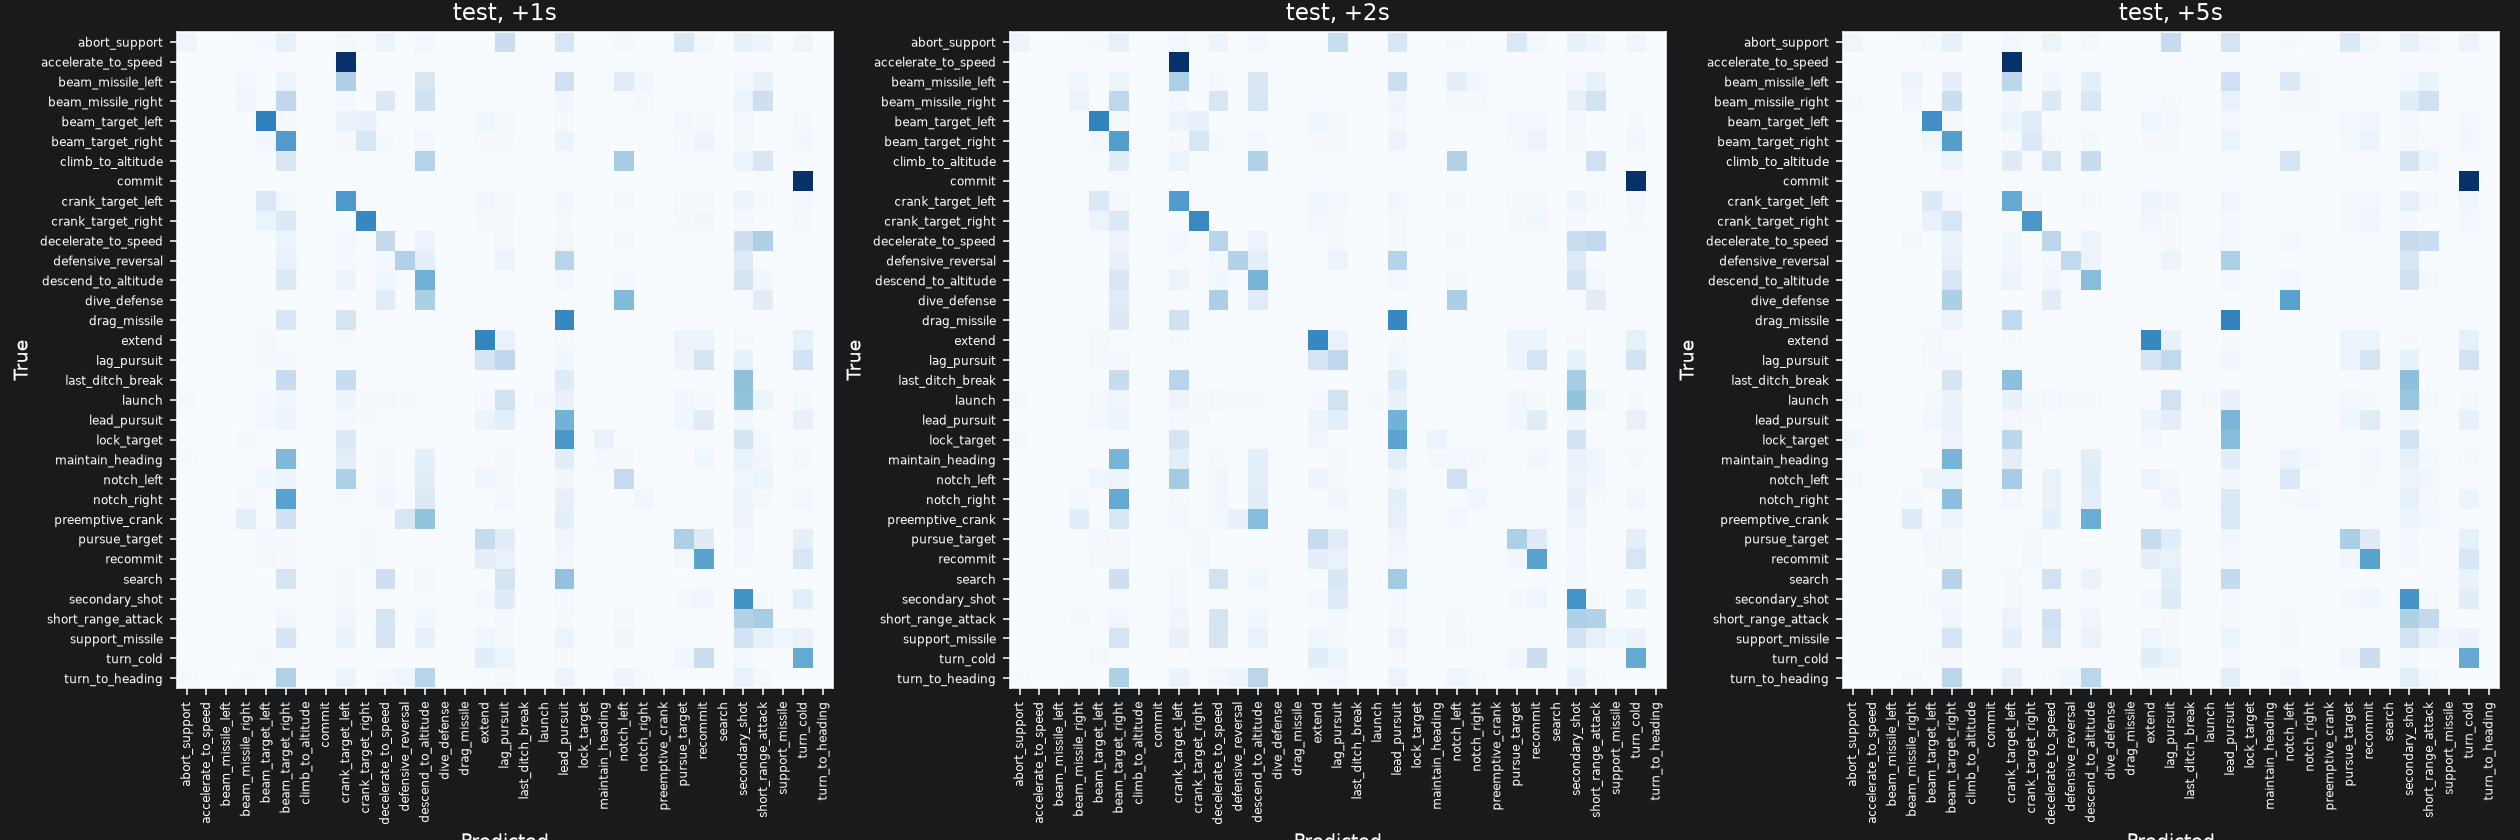

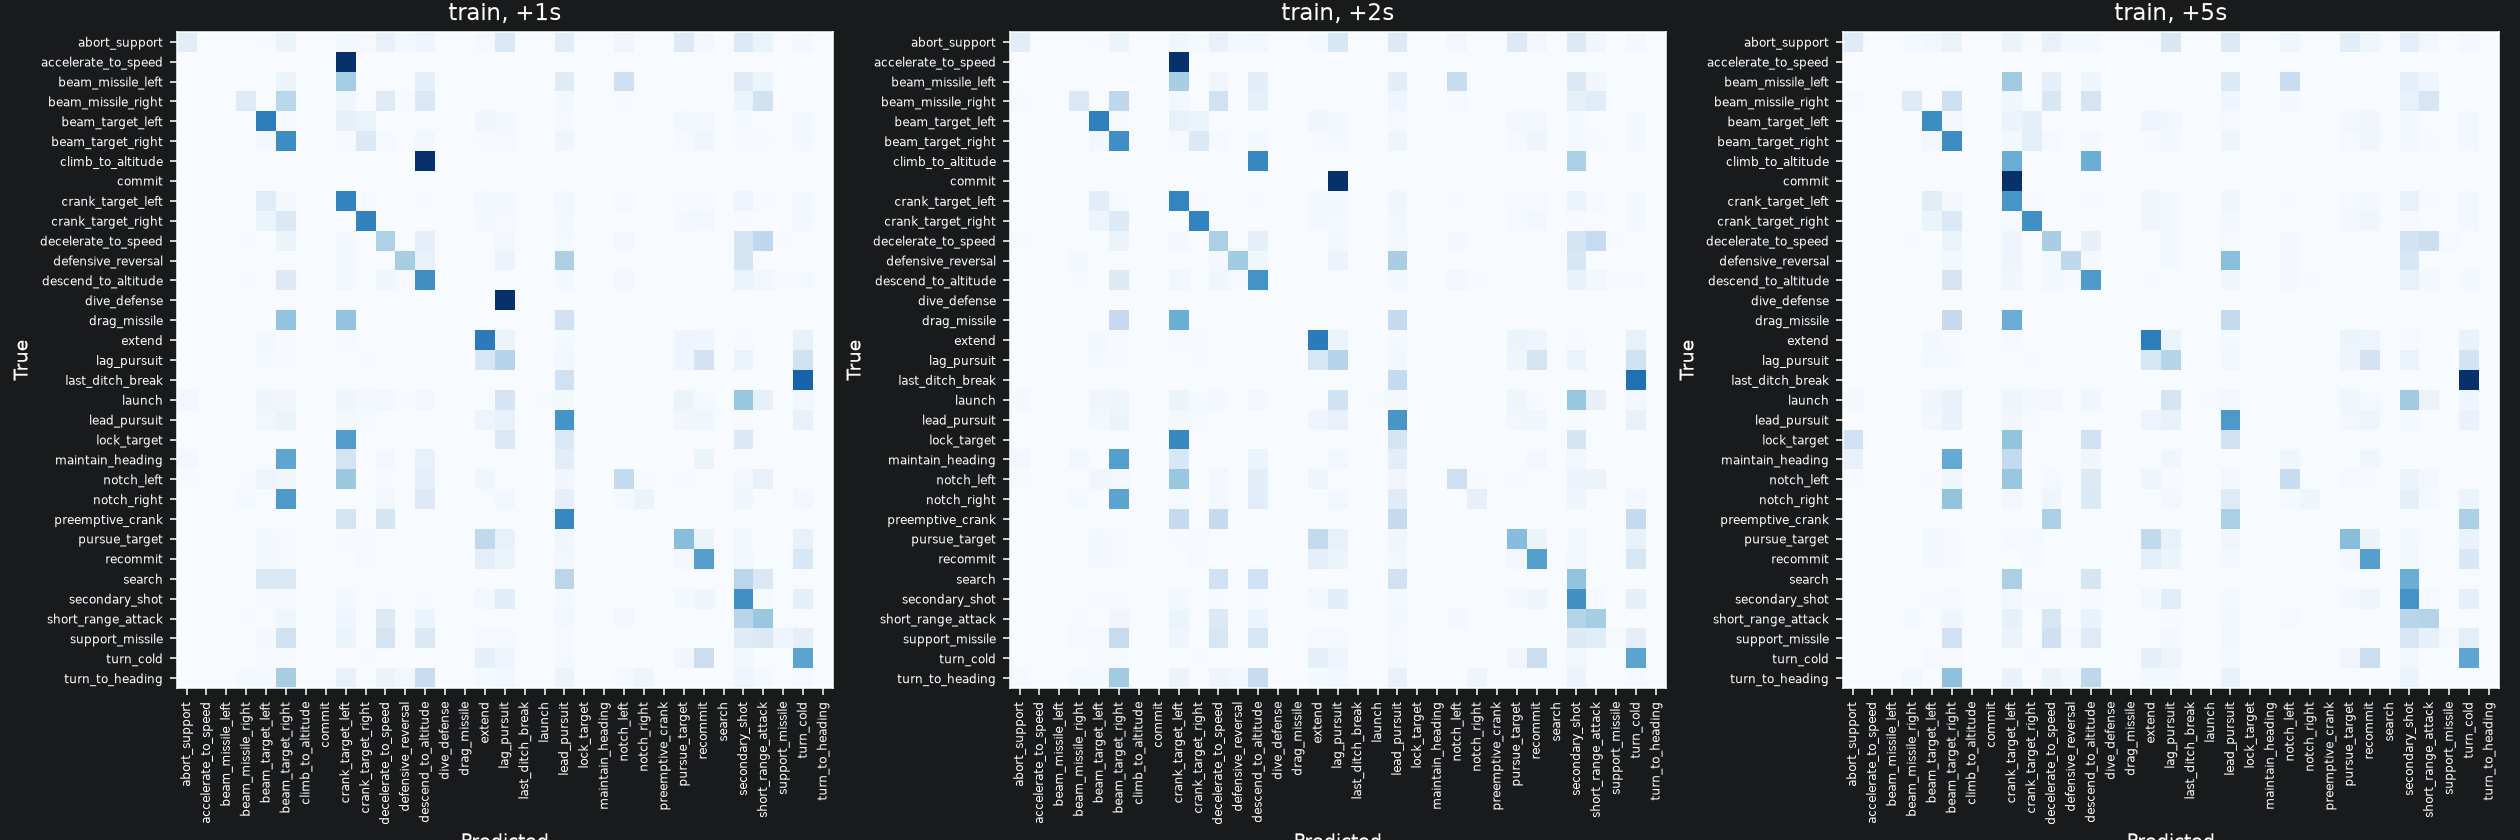

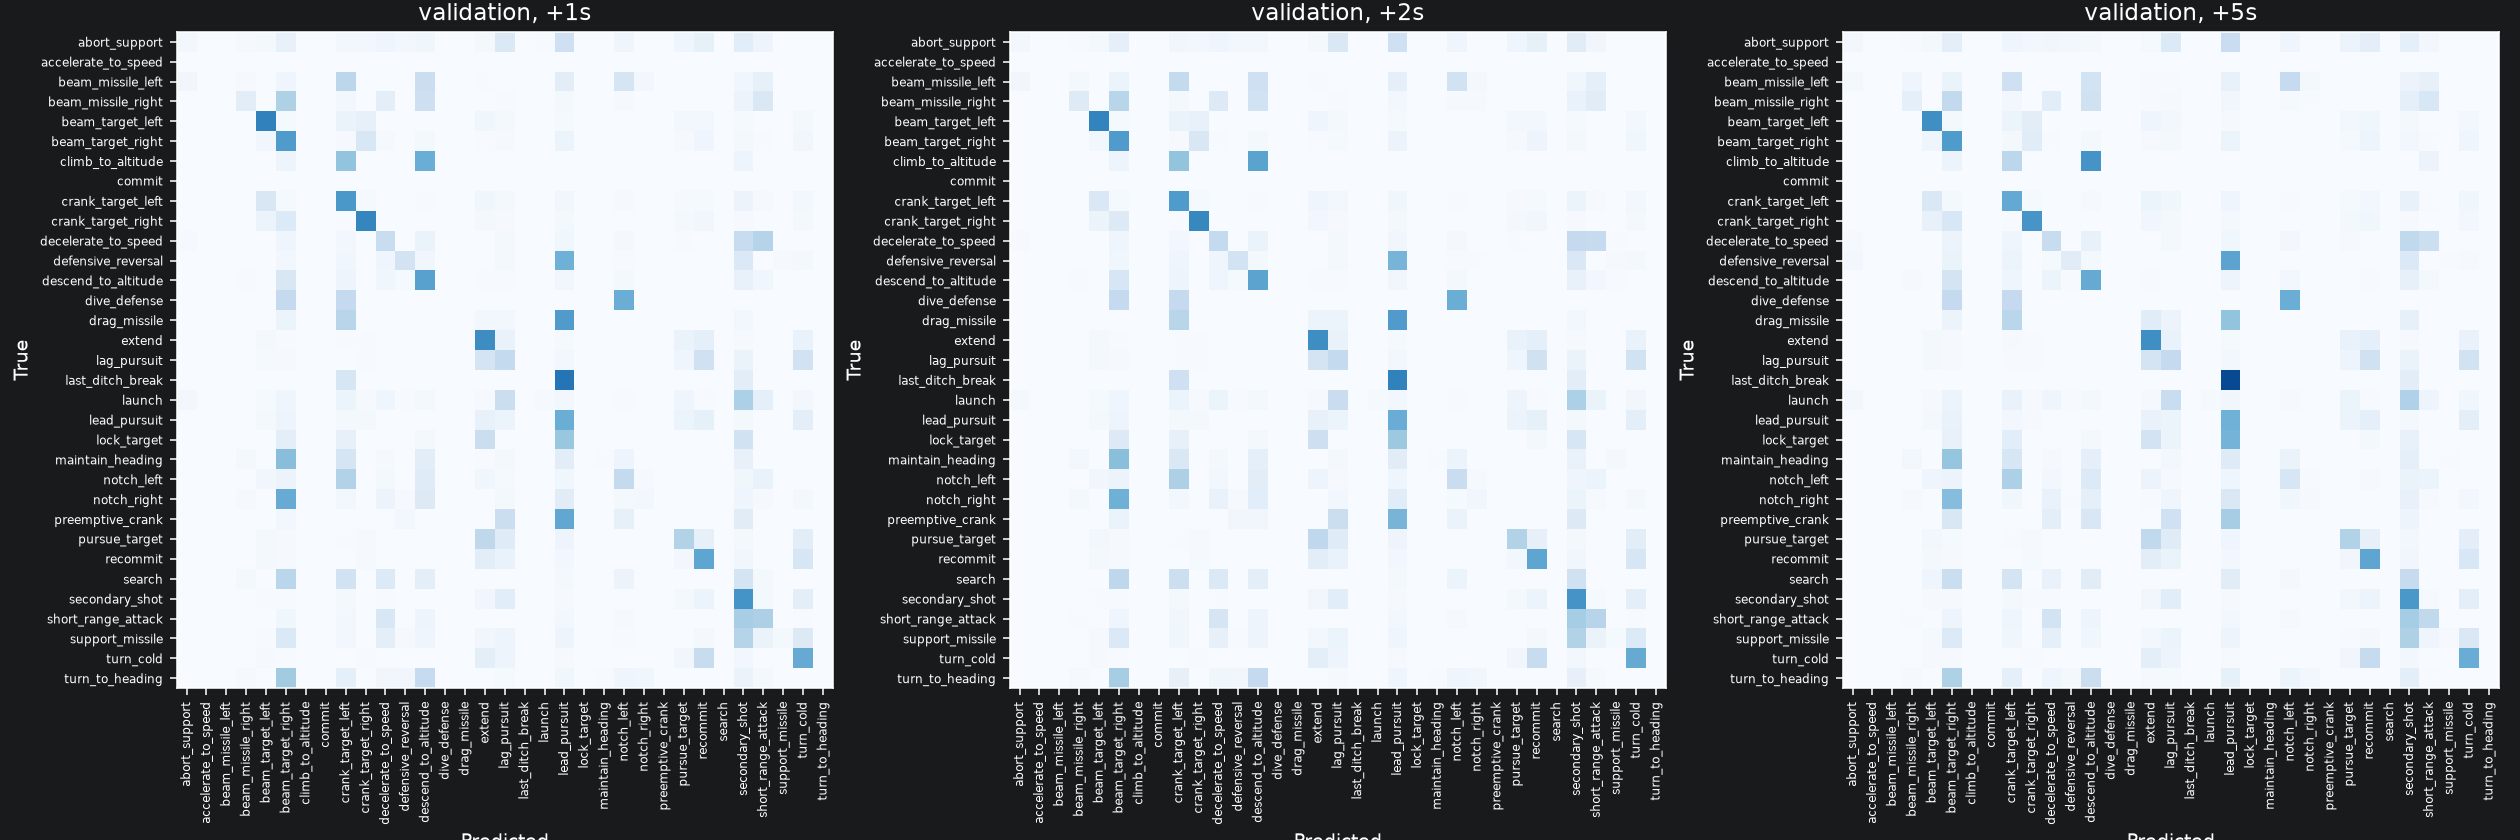

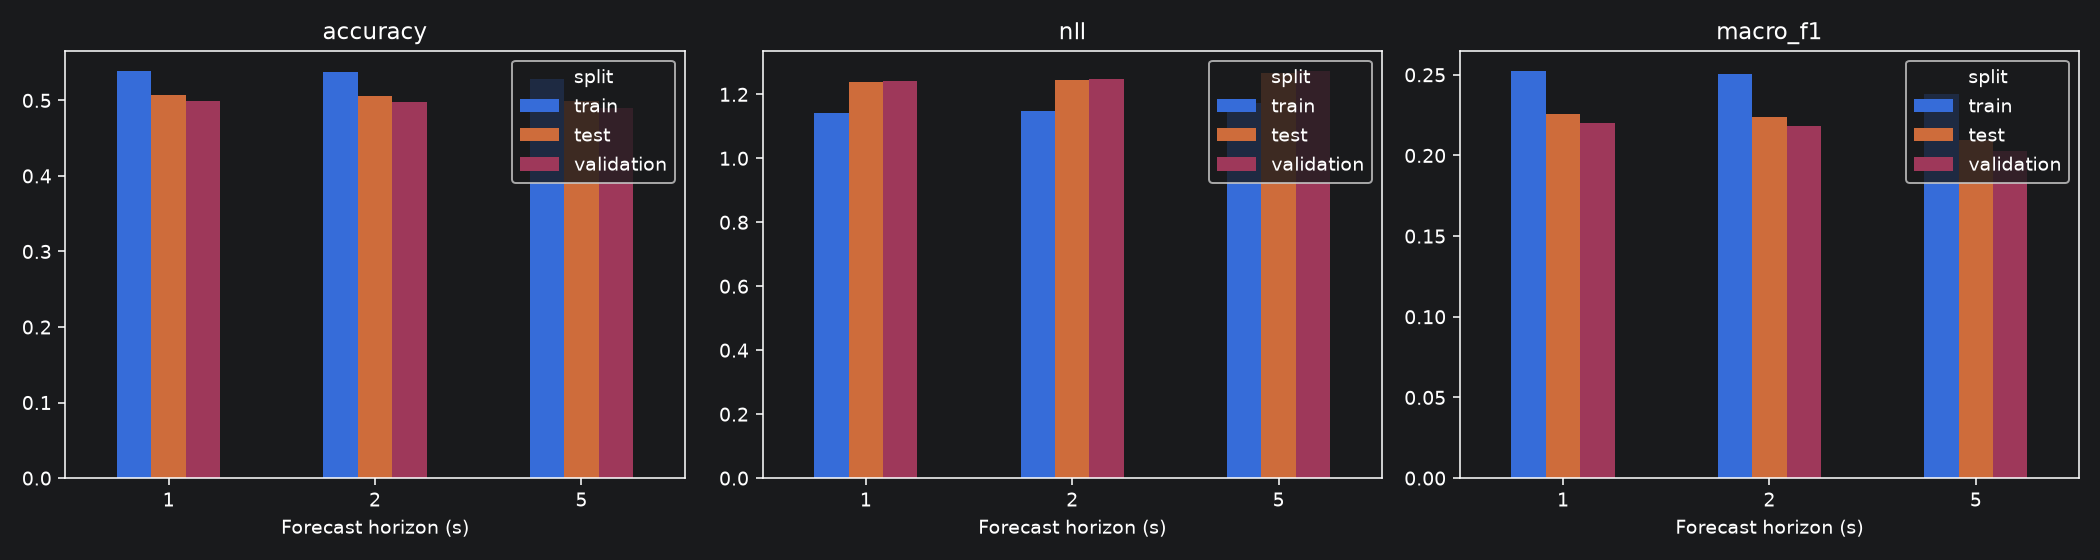

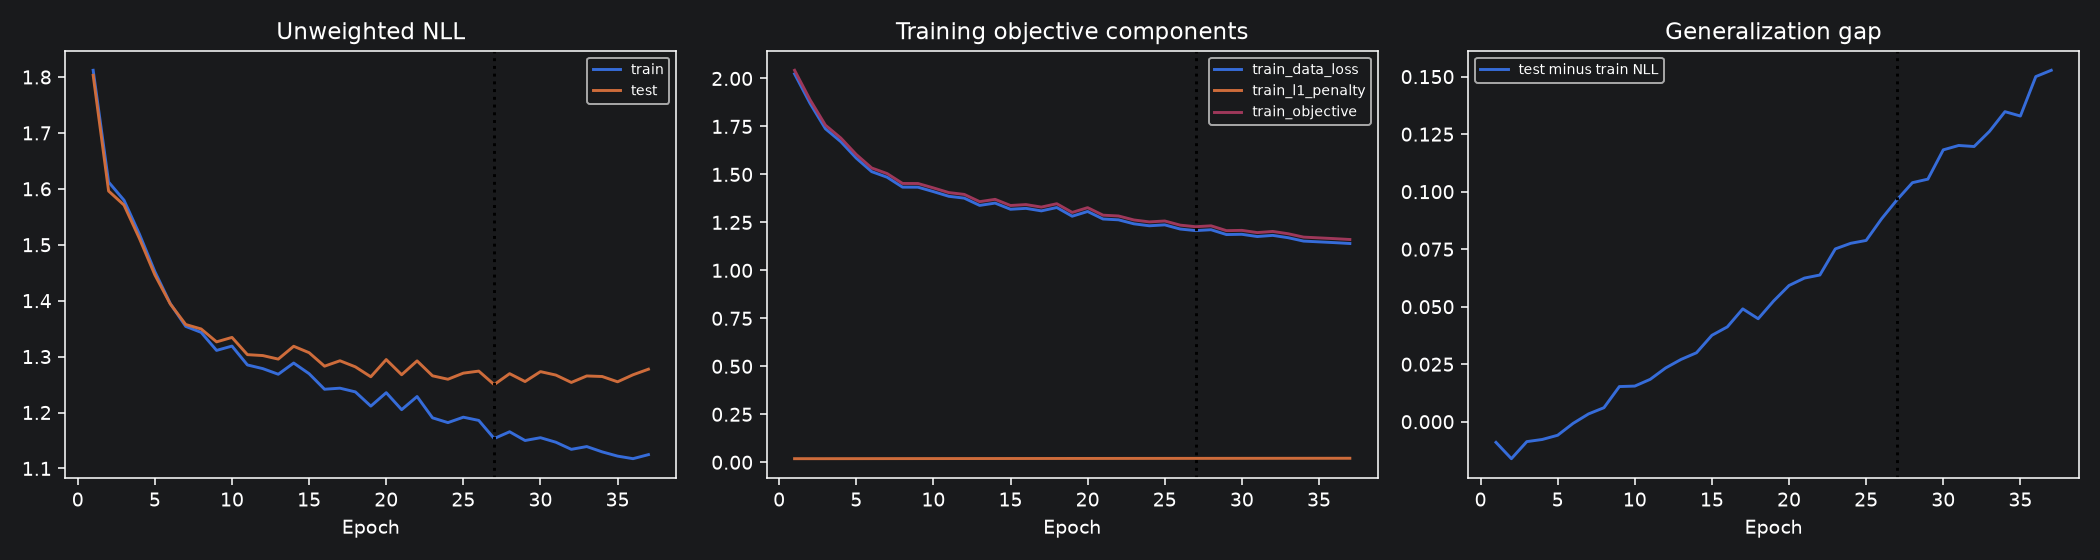

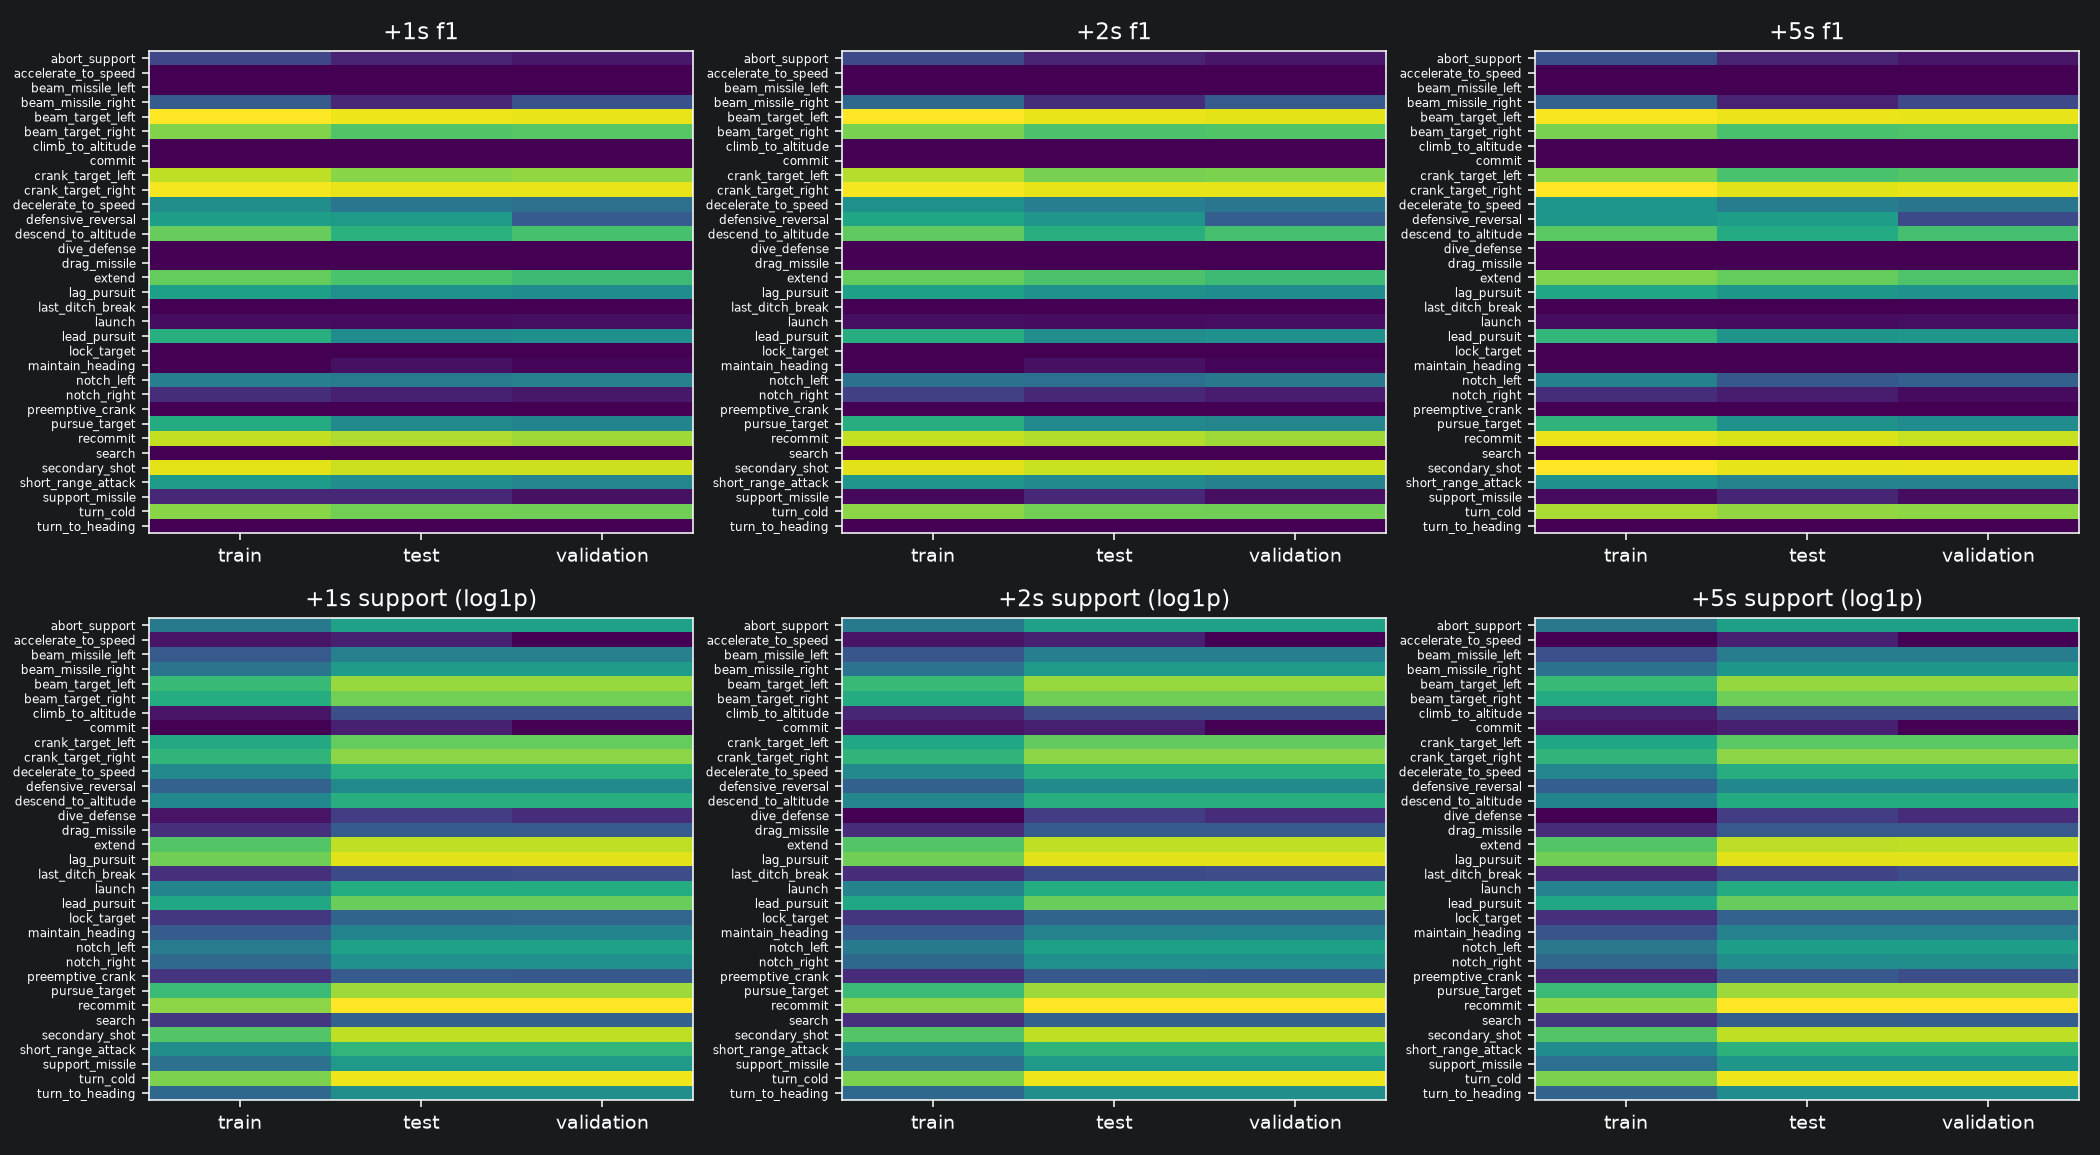

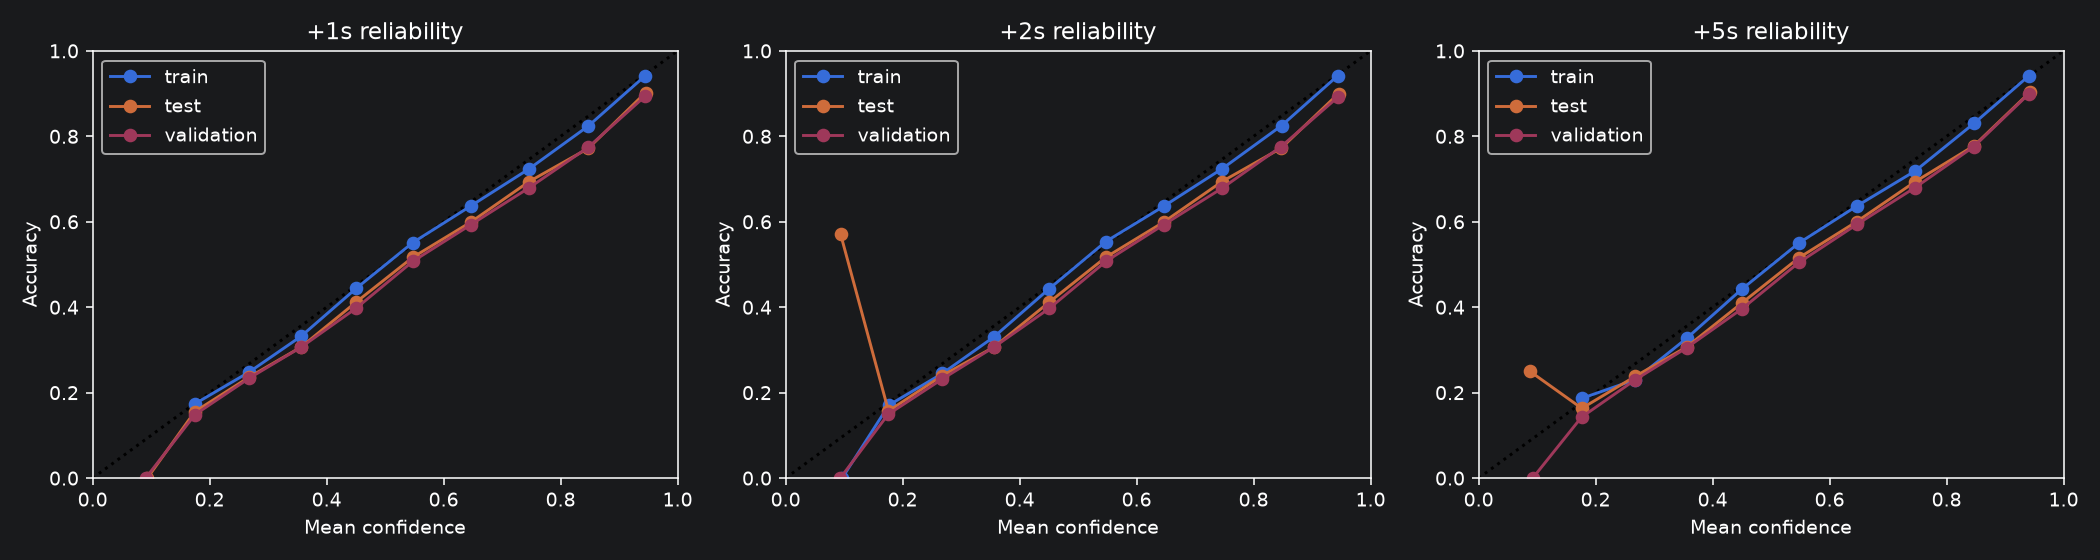

Use notebook 21 to compare the frozen runs across all three architectures.
CPU times: total: 141 ms
Wall time: 391 ms


In [5]:
%%time
from IPython.display import Image

REPORT_SEED = TRAINING_SEEDS[0]  # Chosen before looking at validation results.
RUN = RUNS[REPORT_SEED]
DIAGNOSTICS = RUN / "diagnostics"
print("Saved diagnostic manifest:", DIAGNOSTICS / "manifest.json")
for table_name in ("summary.csv", "per_class.csv", "reliability.csv"):
    path = DIAGNOSTICS / table_name
    if path.is_file():
        print(table_name)
        display(pd.read_csv(path).round(4))
for path in sorted(DIAGNOSTICS.glob("*.png")):
    display(Image(filename=str(path)))
print("Use notebook 21 to compare the frozen runs across all three architectures.")


## Checkpoint inference

Use the shared model factory with the saved model configuration, mean and scale,
then load `model_state`; graph/set models also retain scaling buffers in their
state dict. Input is the same normalised `(batch, 51, 115)` causal history, output
is `(batch, 3, 33)` logits. Refer to `make_model` in
`bvr_behavior_prediction.paired_skill_forecasting` for reconstruction. Retain the
checkpoint's feature ordering, catalogue and horizons. The own-skill block refers
to the observer, never the opponent.

The four enemy slots are channels 54–81; current own-skill indicators start at 82.
Live enemy-missile tracks must match the saved observer-relative North/West/Up
position/velocity scales and raw-zero absence convention. Prepared training
histories remain disjoint across both perspectives of a physical flight. No
future track, opponent decision, pilot identity or outcome enters the encoder.
